> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# IS 4487 Lab 10: Classification Trees with SF Rent Data

## Outline

- Define a binary classification target based on rental price  
- Split the dataset into training and testing sets  
- Fit a Decision Tree Classifier  
- Visualize the decision tree structure  
- Evaluate model accuracy and feature importance  
- Fit and evaluate a Random Forest Classifier
- Fit and evaluate a Gradient Boosting Classifier
- Compare all three classification models

In this lab, we’ll build a classification model to predict whether a rental listing in San Francisco is considered **"affordable"** based on its features.

We are continuing with the **SF Rent dataset** used in **Lab 9**, and will explore how classification trees can uncover patterns in rental prices.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Labs/lab_10_classification.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Overview

**Dataset:** `rent.csv`  
Source: [TidyTuesday-2022-7-05](https://github.com/rfordatascience/tidytuesday/blob/main/data/2022/2022-07-05/rent.csv)

| Variable       | Type       | Description |
|----------------|------------|-------------|
| `post_id`      | Categorical| Unique listing ID |
| `date`         | Numeric    | Listing date (numeric format) |
| `year`         | Integer    | Year of listing |
| `nhood`        | Categorical| Neighborhood |
| `city`         | Categorical| City |
| `county`       | Categorical| County |
| `price`        | Numeric    | Listing price (USD) |
| `beds`         | Numeric    | Number of bedrooms |
| `baths`        | Numeric    | Number of bathrooms |
| `sqft`         | Numeric    | Square footage |
| `room_in_apt`  | Binary     | 1 = room in apartment |
| `address`      | Categorical| Street address |
| `lat`          | Numeric    | Latitude |
| `lon`          | Numeric    | Longitude |
| `title`        | Text       | Listing title |
| `descr`        | Text       | Listing description |
| `details`      | Text       | Additional details |

## Part 1: Clean and Prepare the Data

We'll repeat the cleaning process from Lab 9, including:
- Removing duplicates
- Dropping missing values in key columns
- Filtering out extreme outliers
- Converting data types

### Why This Matters:
Good models depend on clean, reliable inputs.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Load dataset
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/rent.csv'
df = pd.read_csv(url)

# Initial check
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200810 entries, 0 to 200809
Data columns (total 17 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   post_id      200810 non-null  object 
 1   date         200797 non-null  object 
 2   year         200796 non-null  float64
 3   nhood        200796 non-null  object 
 4   city         200796 non-null  object 
 5   county       199402 non-null  object 
 6   price        200796 non-null  float64
 7   beds         194188 non-null  float64
 8   baths        42675 non-null   float64
 9   sqft         64679 non-null   float64
 10  room_in_apt  200796 non-null  float64
 11  address      3908 non-null    object 
 12  lat          7651 non-null    float64
 13  lon          4312 non-null    float64
 14  title        198279 non-null  object 
 15  descr        3254 non-null    object 
 16  details      8015 non-null    object 
dtypes: float64(8), object(9)
memory usage: 26.0+ MB


/tmp/ipykernel_2151/795097367.py:3: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


In [3]:
# Drop duplicate listings using post_id
df = df.drop_duplicates(subset='post_id')

# Drop rows missing essential features
required_cols = ['price', 'beds', 'baths', 'sqft', 'lat', 'lon']
df = df.dropna(subset=required_cols)

# Remove outliers
df = df[df['price'].between(500, 20000)]
df = df[df['beds'].between(0, 10)]
df = df[df['baths'].between(0.5, 10)]
df = df[df['sqft'].between(100, 5000)]

# Convert columns to appropriate data types
df['beds'] = df['beds'].astype(int)
df['baths'] = df['baths'].astype(float)
df['sqft'] = df['sqft'].astype(int)
df['price'] = df['price'].astype(int)

# Reset index
df = df.reset_index(drop=True)

# Quick check
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   post_id      1984 non-null   object 
 1   date         1984 non-null   object 
 2   year         1984 non-null   float64
 3   nhood        1984 non-null   object 
 4   city         1984 non-null   object 
 5   county       1979 non-null   object 
 6   price        1984 non-null   int64  
 7   beds         1984 non-null   int64  
 8   baths        1984 non-null   float64
 9   sqft         1984 non-null   int64  
 10  room_in_apt  1984 non-null   float64
 11  address      1768 non-null   object 
 12  lat          1984 non-null   float64
 13  lon          1984 non-null   float64
 14  title        1855 non-null   object 
 15  descr        1847 non-null   object 
 16  details      1873 non-null   object 
dtypes: float64(5), int64(3), object(9)
memory usage: 263.6+ KB


In [4]:
# Preview data
df.head()

,post_id,date,year,nhood,city,county,price,beds,baths,sqft,room_in_apt,address,lat,lon,title,descr,details
0,4817227421,20141223,2014.0,alameda,alameda,alameda,1939,2,1.0,864,0.0,NaN,37.770600,-122.264800,"LIVE MORE, DRIVE LESS! JUST ACROSS THE BAY FRO...","Summer House Apartments 1826 Poggi St, Alameda...","2BR / 1Ba 864ft2 apartment date=""2014-12-23"" ..."
1,4710888130,20141012,2014.0,alameda,alameda,alameda,2250,2,1.0,1080,0.0,659,37.772835,-122.248585,2br Victortian Duplex Garden Apt.,"This 1903 ""Workingman's Victorian"" on a quiet ...","2BR / 1Ba 1080ft2 apartment date=""2014-11-02""..."
2,5961989126,20170126,2017.0,alameda,alameda,alameda,3995,3,2.0,1787,0.0,NaN,37.759231,-122.247190,3 BR/2 BA Queene Anne on Park St.,This charming 1787 sq ft meticulously maintain...,"3BR / 2Ba1787ft2 data-date=""2017-02-01"" data-t..."
3,4935175730,20150316,2015.0,alameda,alameda,alameda,2536,2,2.0,1225,0.0,NaN,37.753609,-122.249081,Spacious 2BR/2BA in a Great Community!,Tower Apartments CALL US: show contact infox3...,"2BR / 2Ba 1225ft2 apartment date=""2015-04-19""..."
4,4988581576,20150421,2015.0,alameda,alameda,alameda,2650,2,1.0,950,0.0,497,37.758922,-122.263314,"Upgraded 2B w/ Pool View, Short Walk to School...",Enjoy and experience the relaxing atmosphere o...,"2BR / 1Ba 950ft2 apartment date=""2015-04-20"" ..."


## Part 2: Create a Binary Target Variable

We'll classify whether a listing is **Affordable** (price < 3,000).

- 1 = Affordable
- 0 = Not Affordable

### Why This Matters:
To use classification trees, we need a target variable with a limited number of classes.


In [5]:
# Create binary target variable
df['affordable'] = (df['price'] < 3000).astype(int)

# Check target class distribution
df['affordable'].value_counts(normalize=True)


,proportion
affordable,
1,0.611391
0,0.388609


### 🔧 Do the following – Part 2

1. Adjust the affordable threshold to $5,000 and check the class balance again  
2. Calculate what percentage of listings are labeled as affordable



In [6]:
# Add code here
df['affordable'] = (df['price'] < 5000).astype(int)

print("Class counts:")
print(df['affordable'].value_counts())

print("\nClass proportions:")
print(df['affordable'].value_counts(normalize=True))

pct_affordable = df['affordable'].mean() * 100
print(f"\nPercentage of listings labeled as affordable: {pct_affordable:.2f}%")

Class counts:
affordable
1    1820
0     164
Name: count, dtype: int64

Class proportions:
affordable
1    0.917339
0    0.082661
Name: proportion, dtype: float64

Percentage of listings labeled as affordable: 91.73%


Reset the threshold to $3000

In [7]:
# Reset binary target back to 3000
df['affordable'] = (df['price'] < 3000).astype(int)

## Part 3: Select Features and Split Data

We'll use property characteristics as predictors:
- `beds`, `baths`, `sqft`

Then split the data into 80% training and 20% testing.

### Why This Matters:
Train/test splitting ensures our model is evaluated on unseen data.

*Note*: Stratify tells the split to preserve the same class balance in both the training and testing datasets. This is especially important in classification problems when one class is much more common than the other. Without stratification, the test set could accidentally contain too few examples of one class, making the model evaluation less reliable.

In [8]:
# Select features and target
X = df[['beds', 'baths', 'sqft']]
y = df['affordable']

# Create train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Check dimensions
X_train.shape, X_test.shape


((1587, 3), (397, 3))

### 🔧 Reflection - Part 3:
1. What would be the impact if we added `price` as an independent variable?

### ✍️ Your Response: 🔧
1. Adding price would cause target leakage. Affordable is made directly from price and the model would just read the price to get the answer. Accuracy would be good but it wouldn't have learned anything.

## Part 4: Build and Fit the Decision Tree Classifier

We'll train a `DecisionTreeClassifier` on our data.

### Why This Matters:
Decision trees make predictions by splitting data into branches using rules that reduce impurity.


In [9]:
# Initialize classifier
clf = DecisionTreeClassifier(random_state=42)

# Train model on training data
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### Visualize the tree
Pay close attention to how wide and deep the branches reach

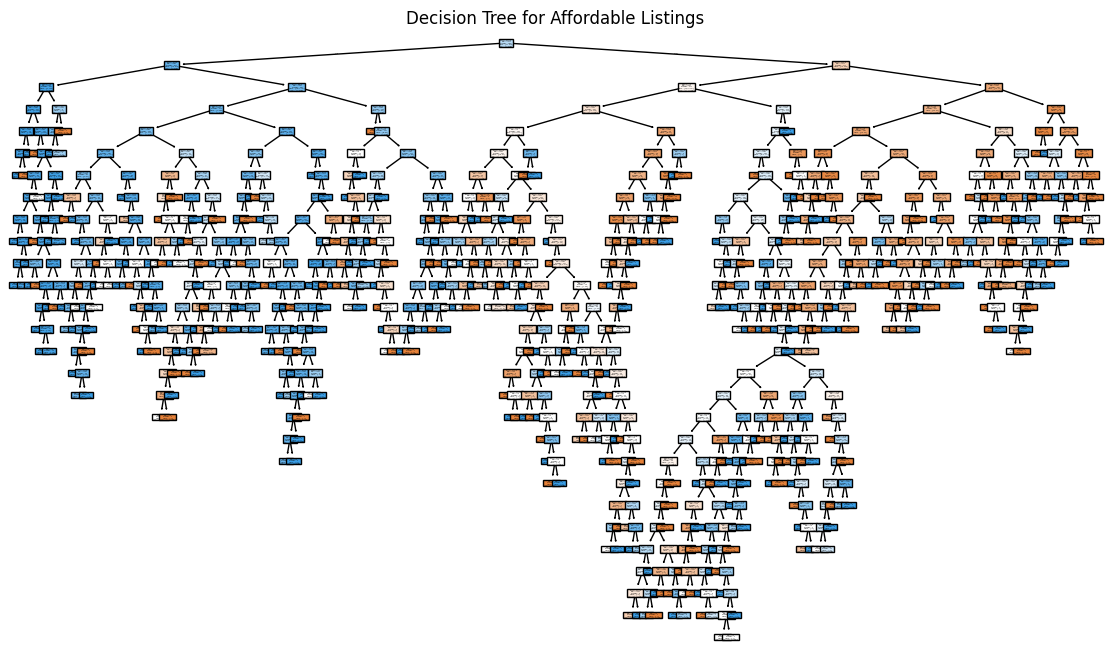

In [10]:
# Plot decision tree
plt.figure(figsize=(14, 8))
plot_tree(clf, feature_names=X.columns, class_names=['Not Affordable', 'Affordable'], filled=True)
plt.title("Decision Tree for Affordable Listings")
plt.show()


### 🔧 Do the following – Part 4

1. Create a second model called `clf_limited` with `max_depth=3`  
2. Fit it on the same training data
3. Visualize this new tree  
> You’ll compare the accuracy of this smaller tree in the next section


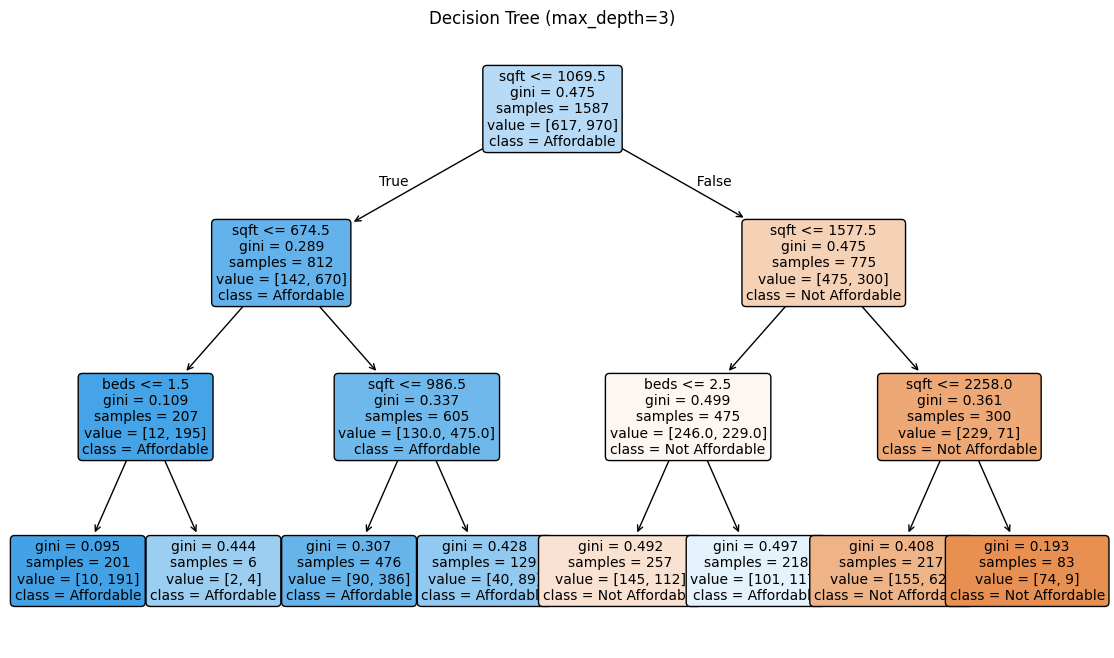

In [11]:
# 🔧 Add code here
clf_limited = DecisionTreeClassifier(max_depth=3, random_state=42)

clf_limited.fit(X_train, y_train)

plt.figure(figsize=(14, 8))
plot_tree(
    clf_limited,
    feature_names=X.columns,
    class_names=['Not Affordable', 'Affordable'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth=3)")
plt.show()

## 5. Evaluate the Model

We’ll check how well the tree performed on the test data using:
- Accuracy score
- Confusion matrix

### Why This Matters:
We want to know how often the model is right and what kind of mistakes it makes.


In [12]:
# Predict on test set
y_pred = clf.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Test Accuracy:", acc)

# Confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Test Accuracy: 0.6801007556675063
Confusion Matrix:
 [[ 89  65]
 [ 62 181]]


### 🔧 Do the following – Part 5

1. Use the `clf_limited` model you created in Part 4 to predict on the test set  
2. Calculate and print the **test accuracy** for `clf_limited`

In [13]:
# 🔧 Add code here
y_pred_limited = clf_limited.predict(X_test)

acc_limited = accuracy_score(y_test, y_pred_limited)
print("Limited Tree Test Accuracy:", acc_limited)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_limited))

Limited Tree Test Accuracy: 0.7355163727959698
Confusion Matrix:
 [[ 93  61]
 [ 44 199]]



### Reflection:
1. Compare the test accuracy of `clf_limited` to the original `clf`. Which performs better?

### ✍️ Your Response: 🔧
1. Clf limited performs better. Limited's test accuracy is 73.6% while regular is 68%. The original has no depth limit so it keeps splitting and causes overfitting.

## Part 6: Evaluate the Tree Feature Importance

We’ll rank the most important predictors.

### Why This Matters:
Tree plots explain the model's logic. Feature importance shows what drives predictions.


In [ ]:
# Plot feature importance
feat_imp = pd.Series(clf.feature_importances_, index=X.columns)
sns.barplot(x=feat_imp.values, y=feat_imp.index)
plt.title("Feature Importance Scores")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


### 🔧 Do the following – Part 6

1. Evaluate the importance of features in the smaller tree, `clf_limited`   

sqft     0.982611
beds     0.017389
baths    0.000000
dtype: float64


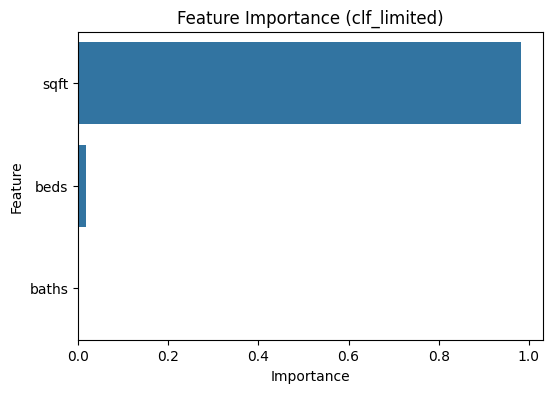

In [14]:
# 🔧 Add code here
importances = pd.Series(clf_limited.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
print(importances)

plt.figure(figsize=(6, 4))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Feature Importance (clf_limited)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


### Reflection:
1. Which feature does the limitted tree split on first?  
2. Is the structure simpler or more complex than the original `clf` tree?

### ✍️ Your Response: 🔧
1. Sqft, the root node asks sqft <= 1069.5. That fits the importance output, where sqft scores 0.983, so it does most of the work in separating affordable listings.
2. Simpler because of the max depth function. The limited tree only has 3 levels of splits and at most 8 leaves, allowing you to easily read each path from top to bottom. Original clf had no limit and kept splitting into more branches and smaller leaves.

## Part 7: Random Forest Classification
A random forest combines predictions from many decision trees. Each tree is trained on a slightly different sample of the data and considers a random subset of features at each split.
### Why This Matters:
A single decision tree can overfit the training data. Random forests often provide more stable and accurate predictions by combining many trees.

In [15]:
# Create a random forest model
rf_clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
rf_clf.fit(X_train, y_train)

# Predict on the test data
rf_pred = rf_clf.predict(X_test)

# Evaluate accuracy
rf_acc = accuracy_score(y_test, rf_pred)
print("Random Forest Test Accuracy:", rf_acc)

# Display confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))

Random Forest Test Accuracy: 0.72544080604534
Confusion Matrix:
 [[ 95  59]
 [ 50 193]]


### Feature Importance in the Random Forest

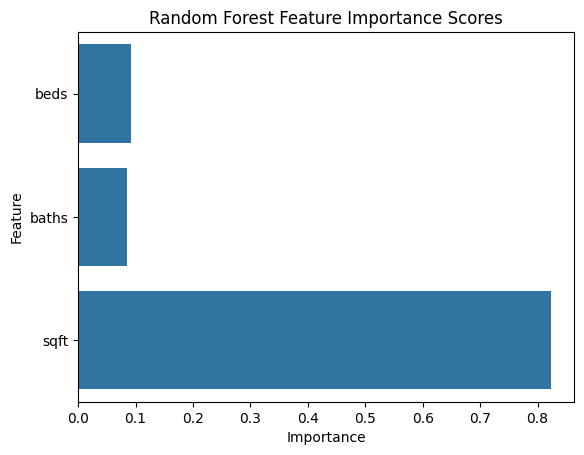

In [16]:
# Create and plot feature importance scores
rf_feat_imp = pd.Series(rf_clf.feature_importances_, index=X.columns)

sns.barplot(x=rf_feat_imp.values, y=rf_feat_imp.index)
plt.title("Random Forest Feature Importance Scores")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### 🔧 Do the following – Part 7
1. Create a second random forest model called rf_limited.
2. Set n_estimators=50 and max_depth=3.
3. Fit the model and calculate its test accuracy.
4. Compare its accuracy to the original random forest.

In [17]:
# 🔧 Add code here
rf_limited = RandomForestClassifier(
    n_estimators=50,
    max_depth=3,
    random_state=42
)

rf_limited.fit(X_train, y_train)

rf_limited_pred = rf_limited.predict(X_test)

rf_limited_acc = accuracy_score(y_test, rf_limited_pred)
print("Limited Random Forest Test Accuracy:", rf_limited_acc)

print("Confusion Matrix:\n", confusion_matrix(y_test, rf_limited_pred))

print("\nOriginal RF Accuracy:", rf_acc)
print("Limited RF Accuracy: ", rf_limited_acc)

Limited Random Forest Test Accuracy: 0.707808564231738
Confusion Matrix:
 [[ 87  67]
 [ 49 194]]

Original RF Accuracy: 0.72544080604534
Limited RF Accuracy:  0.707808564231738


### Reflection:
1. Why might a random forest perform better than one decision tree?
2. Does limiting the depth of each tree appear to improve or reduce test accuracy?
### ✍️ Your Response: 🔧
1. A forest averages many trees trained on different random samples, so their individual mistakes tend to cancel out. That makes predictions more stable and less prone to overfitting than a single tree.
2. It reduced accuracy, .708 vs .725. A forest already controls overfitting by averaging, so capping depth just makes each tree too simple.

## Part 8: Gradient Boosting Classification
Gradient boosting is another ensemble method. Unlike a random forest, which builds many independent trees, gradient boosting builds trees one at a time. Each new tree focuses on improving errors made by the earlier trees.
### Why This Matters:
Gradient boosting can create a strong predictive model from many small, simple trees. However, it may require careful tuning to avoid overfitting.

In [18]:
# Create a gradient boosting model
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_clf.fit(X_train, y_train)

# Predict on the test data
gb_pred = gb_clf.predict(X_test)

# Evaluate accuracy
gb_acc = accuracy_score(y_test, gb_pred)
print("Gradient Boosting Test Accuracy:", gb_acc)

# Display confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, gb_pred))

Gradient Boosting Test Accuracy: 0.7355163727959698
Confusion Matrix:
 [[ 88  66]
 [ 39 204]]


### Feature Importance in Gradient Boosting

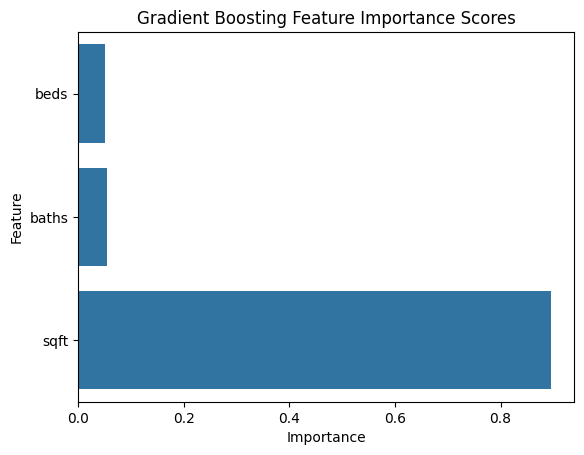

In [19]:
# Create and plot feature importance scores
gb_feat_imp = pd.Series(gb_clf.feature_importances_, index=X.columns)

sns.barplot(x=gb_feat_imp.values, y=gb_feat_imp.index)
plt.title("Gradient Boosting Feature Importance Scores")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### 🔧 Do the following – Part 8
1. Create a second gradient boosting model called gb_slow.
2. Set learning_rate=0.05 and n_estimators=200.
3. Fit the model and calculate its test accuracy.
4. Compare the result to the original gradient boosting model.

In [20]:
# 🔧 Add code here
gb_slow = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_slow.fit(X_train, y_train)
gb_slow_pred = gb_slow.predict(X_test)
gb_slow_acc = accuracy_score(y_test, gb_slow_pred)

print("Slow Gradient Boosting Test Accuracy:", gb_slow_acc)
print("Confusion Matrix:\n", confusion_matrix(y_test, gb_slow_pred))

print("\nOriginal GB Accuracy:", gb_acc)
print("Slow GB Accuracy:    ", gb_slow_acc)

Slow Gradient Boosting Test Accuracy: 0.7355163727959698
Confusion Matrix:
 [[ 87  67]
 [ 38 205]]

Original GB Accuracy: 0.7355163727959698
Slow GB Accuracy:     0.7355163727959698


### Reflection:
1. What is the tradeoff between using a smaller learning rate and more trees?
2. Which feature is most important in the gradient boosting model?
3. Is the most important feature consistent across the decision tree, random forest, and gradient boosting models?
### ✍️ Your Response: 🔧
1. Smaller learning raters make each tree contribute less, which usually generalizes better and overfits less. The downside is that you need more trees to reach the same fit, so training takes longer. However, there was no difference in accuracy here.
2. Sqft, at around 0.9, beds and baths are each at around 0.05
3. Yes, sqft dominates all three models. Importance has little spread in random forest and gradient boosting due to number of trees utilized, while single tree relied almost entirely on sqft.

## Part 9: Compare Model Performance
Now, compare the accuracy of the four main models:
- Full decision tree
- Limited-depth decision tree
- Random forest
- Gradient boosting

In [21]:
# Create a comparison table
model_results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Limited Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Test Accuracy': [
        acc,
        accuracy_score(y_test, clf_limited.predict(X_test)),
        rf_acc,
        gb_acc
    ]
})

model_results.sort_values(by='Test Accuracy', ascending=False)

,Model,Test Accuracy
1,Limited Decision Tree,0.735516
3,Gradient Boosting,0.735516
2,Random Forest,0.725441
0,Decision Tree,0.680101


### 🔧 Do the following – Part 9
1. Add your rf_limited and gb_slow models to the comparison table.
2. Identify the model with the highest test accuracy.
3. Create a bar chart showing the test accuracy of each model.

                    Model  Test Accuracy
0   Limited Decision Tree       0.735516
1  Slow Gradient Boosting       0.735516
2       Gradient Boosting       0.735516
3           Random Forest       0.725441
4   Limited Random Forest       0.707809
5      Full Decision Tree       0.680101

Best model(s):
['Limited Decision Tree', 'Slow Gradient Boosting', 'Gradient Boosting']


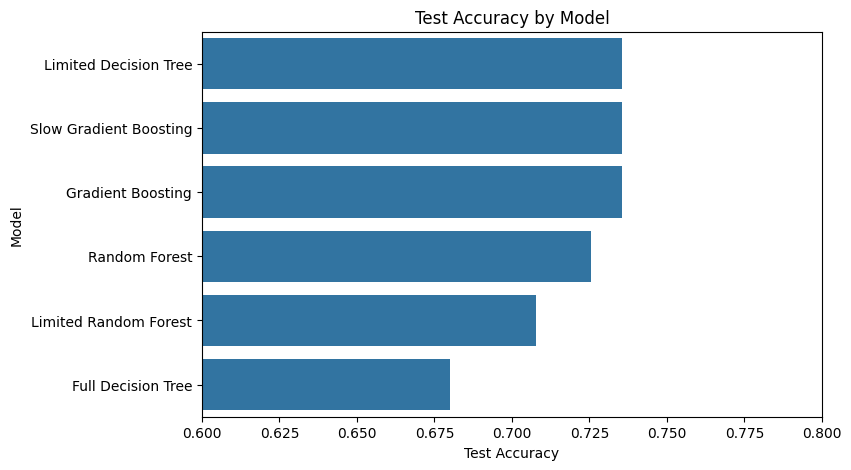

In [22]:
# 🔧 Add code here
models = {
    'Full Decision Tree': clf,
    'Limited Decision Tree': clf_limited,
    'Random Forest': rf_clf,
    'Limited Random Forest': rf_limited,
    'Gradient Boosting': gb_clf,
    'Slow Gradient Boosting': gb_slow,
}

results = pd.DataFrame({
    'Model': list(models.keys()),
    'Test Accuracy': [accuracy_score(y_test, m.predict(X_test)) for m in models.values()]
}).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

print(results)

best_acc = results['Test Accuracy'].max()
print("\nBest model(s):")
print(results[results['Test Accuracy'] == best_acc]['Model'].to_list())

plt.figure(figsize=(8, 5))
sns.barplot(x='Test Accuracy', y='Model', data=results)
plt.title("Test Accuracy by Model")
plt.xlim(0.6, 0.8)
plt.show()

## 🔧 Part 10: Final Reflection (100 words or less per question)
1. Which model had the best test accuracy? Does that automatically make it the best model for every business situation?
2. Compare a decision tree, random forest, and gradient boosting model in terms of interpretability. Which would be easiest to explain to a landlord or property manager?
3. Would you trust one of these models to recommend rental prices to landlords? What additional variables or safeguards would you want before using it in practice?



### ✍️ Your Response: 🔧
1. Three models tied at 0.735. Accuracy alone doesn't make any of them the best for every situation. The right model depends on which mistake would affect you more. Since three are tied for the lead, you can pick and choose one based on other things such as simplicity for your business problem or explainability of the output.
2. The decision tree is the easiest to explain. You can show someone unfamiliar with analytics the diagram and easily walk them through how the model functions. Random forest and gradient boosting don't have as straightforward of guidelines.
3. Not in the current stage. Accuracy is only at 74% roughly, and this model classifies affordable or not rather than outputting a nominal price. I would like to incorporate more variable such as neighborhood, year built, etc. Safeguards could be retraining the model at certain time intervals to keep up with the latest market trends, and even possibly add human review.

## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_10_classification.ipynb"